# Dimension Reduction

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from rich import print, pretty
pretty.install()
print(f"Original number of columns: {len(pd.read_csv("../../SyntheticData_Training.csv").columns)}")
data = pd.read_csv("../../cleaned_dataset.csv")
target = "inhospital_mortality"  # save target column
display(data.head())

with pd.option_context('display.max_colwidth', None, 'display.max_rows', None, 'display.max_columns', None):
    display(data.columns)

Original number of columns: 140

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,caregiver_adm_new,inhospital_mortality,age_group
0,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,99.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,Mother,0,Toddler (12-23m)
1,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,92.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,Mother,0,Preschool-3 (36-47m)
2,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,99.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,Mother,0,Baby (6-11m)
3,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,98.0,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,Yes,HIV negative,Yes,Mother,0,Preschool-3 (36-47m)
4,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,90.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,Mother,0,Toddler (12-23m)



Index(['agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm',
       'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm', 'diasbp_mmhg_adm',
       'temp_c_adm', 'spo2site1_pc_oxi_adm',
       ...
       'cookloc_adm', 'lightfuel_adm', 'tobacco_adm', 'bednet_adm',
       'hctpretransfusion_adm', 'hivstatus_adm', 'malariastatuspos_adm',
       'caregiver_adm_new', 'inhospital_mortality', 'age_group'],
      dtype='object', length=112)

In [2]:
# fill in missing values using 'most frequent' for categorical
# and 'median' for numerical values

import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

# Check for missing values before imputing
print(f"Missing values before imputation: {data.isna().sum().sum()}")

# Separate numerical and categorical columns
numerical_cols = data.select_dtypes(include=['number']).columns
categorical_cols = data.select_dtypes(exclude=['number']).columns

# Create imputers
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

# Impute missing values for numerical and categorical columns
if not numerical_cols.empty:
    data[numerical_cols] = num_imputer.fit_transform(data[numerical_cols])
if not categorical_cols.empty:
    data[categorical_cols] = cat_imputer.fit_transform(data[categorical_cols])

# Check for missing values after imputing
print(f"Missing values after imputation: {data.isna().sum().sum()}")


Missing values before imputation: 30

Missing values after imputation: 0

In [3]:

len(numerical_cols), len(categorical_cols)

(22, 90)

# Dimensionality Reduction strategy.
- Apply MCA to categorical features, PCA to numerical features, `hstack` both results and further reduce to 3 dimensions.

In [4]:
import matplotlib.pyplot as plt

def pie_chart(sorted_contrib, dim, threshold=0.5):
    # Use the top_features_to_50_percent function to select features
    selected_features, _ = top_features_to_50_percent(sorted_contrib, threshold)

    # Create labels: selected features retain their labels, others are grouped as "Others"
    top_contrib = sorted_contrib.loc[selected_features]
    other_contrib = sorted_contrib.drop(selected_features).sum()

    labels = list(top_contrib.index) + ["Others"]
    values = list(top_contrib.values) + [other_contrib]

    # Pie chart for contributions
    plt.figure(figsize=(10, 10))
    plt.pie(values, labels=labels, autopct='%1.1f%%', startangle=140, 
            labeldistance=None if len(labels) > 10 else 1.1)  # Hide labels if too many
    plt.title(f"Contributions to {dim} (Top {threshold*100:.0f}%)")
    plt.axis('equal')
    plt.legend(labels, loc="upper right", bbox_to_anchor=(1.1, 1))  # Legend for visibility
    plt.show()

def top_features_to_50_percent(sorted_contrib, threshold=0.5):
    cumulative_sum = 0
    selected_features = []

    for feature, value in sorted_contrib.items():
        if cumulative_sum + value > threshold:
            break
        cumulative_sum += value
        selected_features.append(feature)

    return selected_features, cumulative_sum


0             1  \
sex_adm__Female                                   1.088304e-06  5.613161e-07   
sex_adm__Male                                     9.445086e-07  4.871506e-07   
spo2onoxy_adm__No                                 5.589981e-05  5.776677e-03   
spo2onoxy_adm__Yes                                3.611749e-04  3.732375e-02   
oxygenavail_adm__Oxygen available and being used  1.769339e-04  2.506430e-02   
...                                                        ...           ...   
age_group__Baby (6-11m)                           5.692838e-03  1.015053e-03   
age_group__Preschool-2 (24-35m)                   2.526308e-03  7.153297e-04   
age_group__Preschool-3 (36-47m)                   2.810338e-03  1.106088e-03   
age_group__Preschool-4 (48-59m)                   2.415171e-03  1.380181e-04   
age_group__Toddler (12-23m)                       3.367830e-04  1.101217e-04   

                                                         2  
sex_adm__Female                                   0.000002  
sex_adm__Male                                     0.000002  
spo2onoxy_adm__No                                 0.003551  
spo2onoxy_adm__Yes                                0.022945  
oxygenavail_adm__Oxygen available and being used  0.018304  
...                                                    ...  
age_group__Baby (6-11m)                           0.004256  
age_group__Preschool-2 (24-35m)                   0.000952  
age_group__Preschool-3 (36-47m)                   0.001679  
age_group__Preschool-4 (48-59m)                   0.000680  
age_group__Toddler (12-23m)                       0.000026  

[262 rows x 3 columns]

{np.float64(0.9999999999999997), np.float64(1.0000000000000004), np.float64(0.999999999999996)}

Dimension 1 (Sorted Contributions):

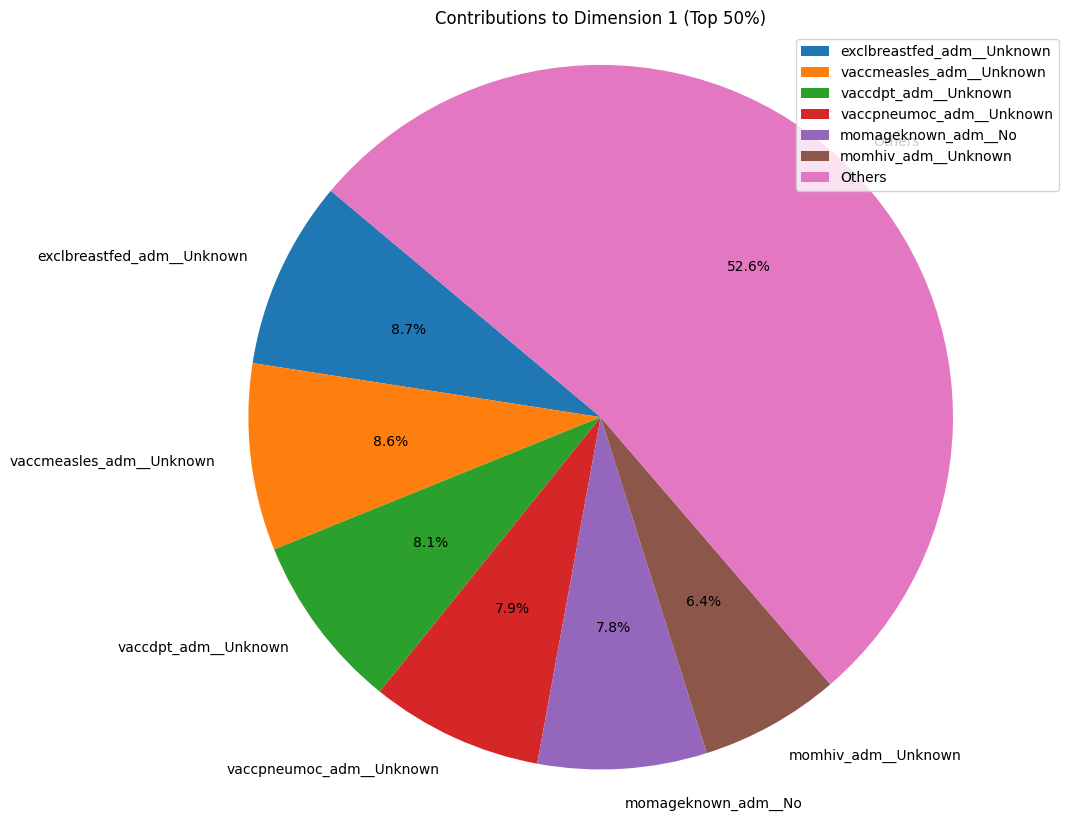

Dimension 2 (Sorted Contributions):

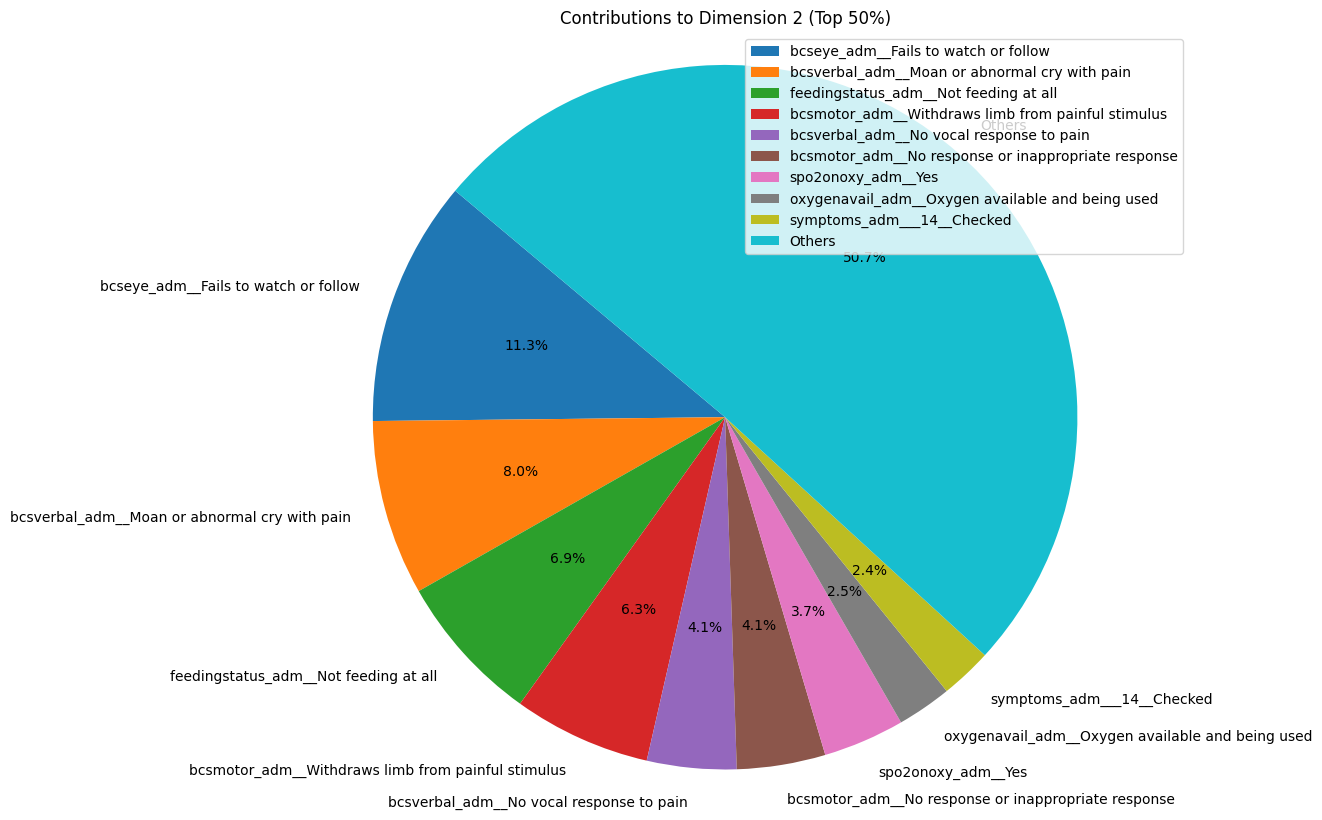

Dimension 3 (Sorted Contributions):

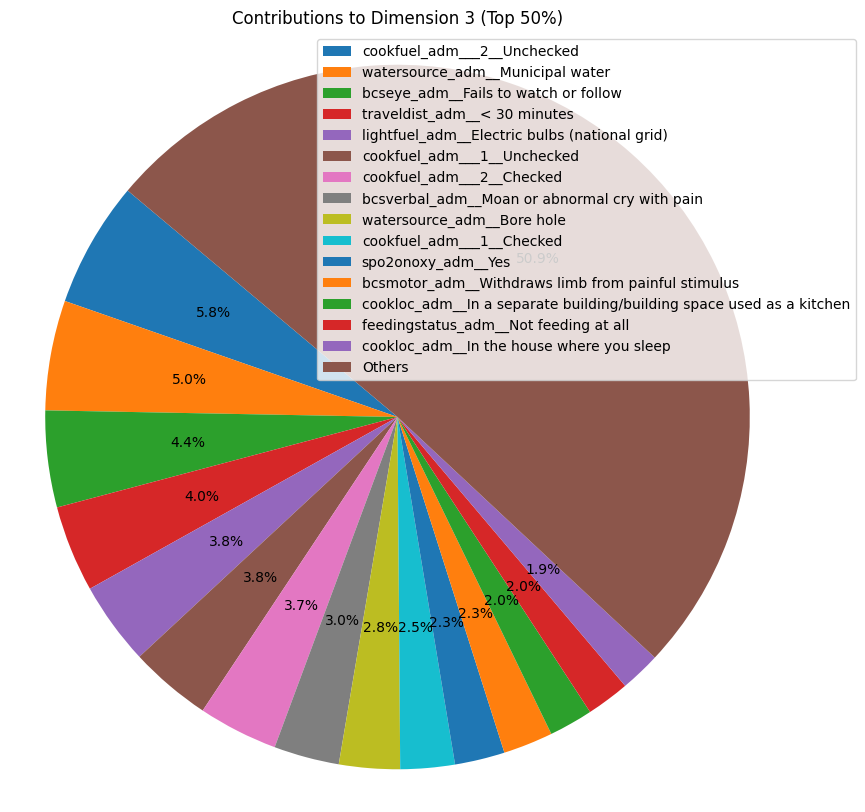

In [5]:
import pandas as pd
from prince import MCA
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np

# Separate categorical and numerical columns
categorical_cols = data.select_dtypes(exclude=['number']).columns
numerical_cols = data.select_dtypes(include=['number']).columns

# Perform MCA on categorical columns
if not categorical_cols.empty:
    df_categorical = data[categorical_cols]
    mca = MCA(n_components=3)
    mca = mca.fit(df_categorical)

    # Get column contributions (categories)
    column_contributions = mca.column_contributions_
    # Convert contributions to a DataFrame for easier handling
    contributions_df = pd.DataFrame(column_contributions)
    print(contributions_df)

    # Sort contributions for each dimension
    sorted_contributions = {
        f"Dimension {dim+1}": contributions_df[dim].sort_values(ascending=False)
        for dim in range(contributions_df.shape[1])
    }
    print({v.sum() for k, v in sorted_contributions.items()})

    # Display sorted contributions
    for dim, sorted_contrib in sorted_contributions.items():
        print(f"\n{dim} (Sorted Contributions):")
        # print(sorted_contrib)
        pie_chart(sorted_contrib, dim)
        
else:
    print("No categorical columns to process.")

In [6]:
def diverging_bar_plot(sorted_contrib, dim):
    # Separate positive and negative contributions
    pos_contrib = sorted_contrib[sorted_contrib > 0]
    neg_contrib = sorted_contrib[sorted_contrib < 0]

    # Combine contributions for the plot
    combined_contrib = pd.concat([neg_contrib, pos_contrib]).sort_values()

    # Plot
    plt.figure(figsize=(10, 8))
    combined_contrib.plot(kind='barh', color=combined_contrib.apply(lambda x: 'red' if x < 0 else 'blue'))
    plt.axvline(0, color='black', linewidth=0.8, linestyle='--')  # Zero line
    plt.axvline(0.2, color='gray', linewidth=0.8, linestyle='--')  # Vertical line at 0.2
    plt.axvline(-0.2, color='gray', linewidth=0.8, linestyle='--')  # Vertical line at -0.2
    plt.title(f"Contributions to {dim}")
    plt.xlabel("Contribution Value")
    plt.ylabel("Features")
    plt.tight_layout()
    plt.show()



PCA Explained Variance Ratio (Numerical Features): [0.15754884 0.10417665 0.09045952]

Principal Component 1 (Sorted Contributions):

height_cm_adm           0.471392
weight_kg_adm           0.470944
agecalc_adm             0.440372
muac_mm_adm             0.358954
spo2site2_pc_oxi_adm    0.219759
spo2site1_pc_oxi_adm    0.206564
momage_adm              0.144376
alivechildren_adm       0.092141
householdsize_adm       0.086784
sqi2_perc_oxi_adm       0.081289
sqi1_perc_oxi_adm       0.075608
momagefirstpreg_adm     0.050288
diasbp_mmhg_adm         0.033766
deadchildren_adm        0.025034
lactate_mmolpl_adm      0.024003
hematocrit_gpdl_adm     0.015457
glucose_mmolpl_adm      0.007043
sysbp_mmhg_adm         -0.002295
inhospital_mortality   -0.035108
temp_c_adm             -0.060200
hr_bpm_adm             -0.160527
rr_brpm_app_adm        -0.239336
Name: 0, dtype: float64

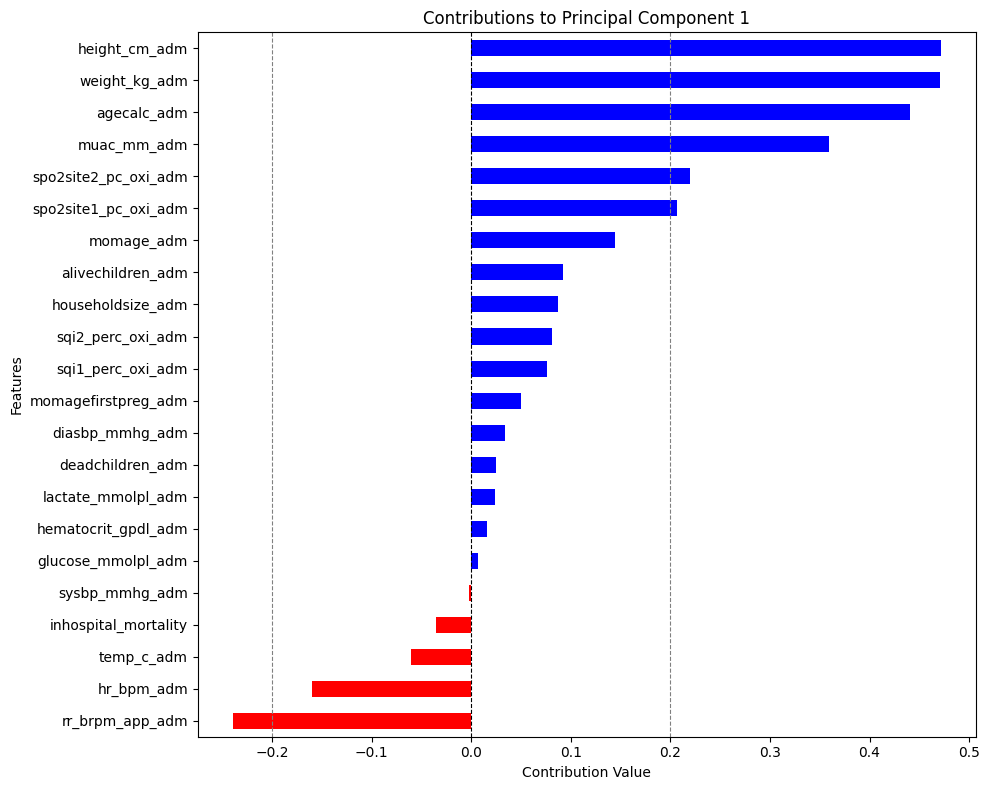

Principal Component 2 (Sorted Contributions):

alivechildren_adm       0.437862
householdsize_adm       0.405181
momage_adm              0.322408
deadchildren_adm        0.243641
rr_brpm_app_adm         0.235132
diasbp_mmhg_adm         0.177398
sysbp_mmhg_adm          0.140816
hr_bpm_adm              0.137937
lactate_mmolpl_adm      0.137796
temp_c_adm              0.131855
glucose_mmolpl_adm      0.116713
agecalc_adm             0.095497
height_cm_adm           0.080775
weight_kg_adm           0.080647
muac_mm_adm             0.001713
inhospital_mortality   -0.000539
momagefirstpreg_adm    -0.018842
hematocrit_gpdl_adm    -0.090387
sqi1_perc_oxi_adm      -0.125953
sqi2_perc_oxi_adm      -0.161844
spo2site2_pc_oxi_adm   -0.339160
spo2site1_pc_oxi_adm   -0.342673
Name: 1, dtype: float64

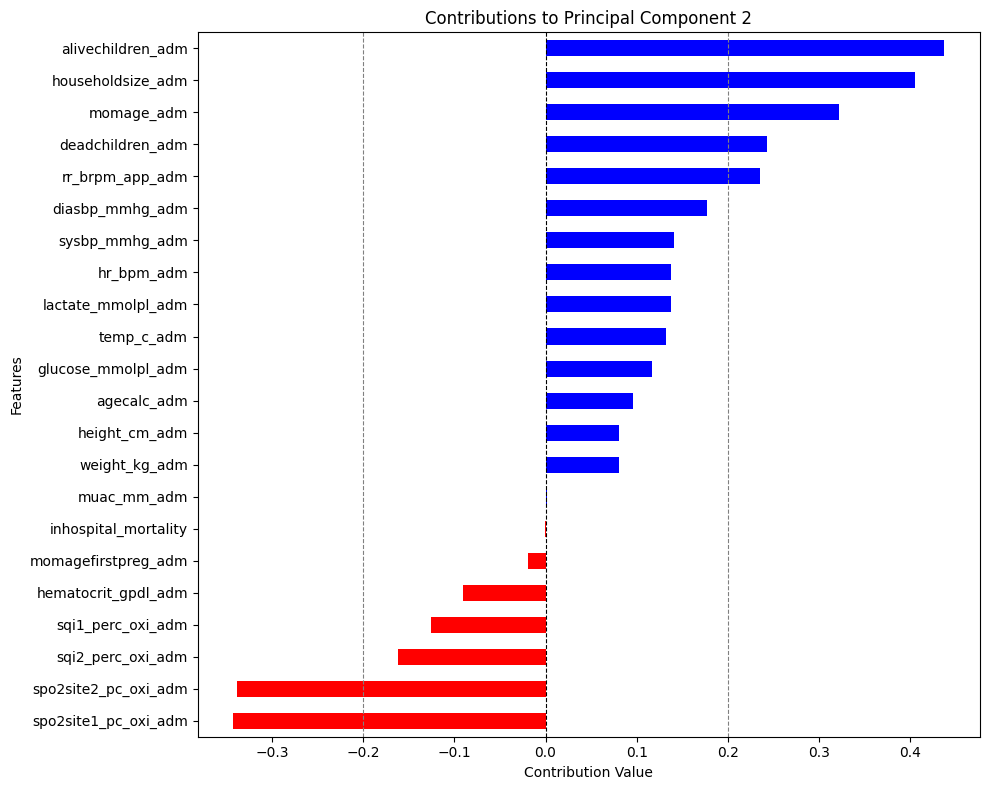

Principal Component 3 (Sorted Contributions):

alivechildren_adm       0.380339
householdsize_adm       0.378929
spo2site1_pc_oxi_adm    0.323696
spo2site2_pc_oxi_adm    0.315345
momage_adm              0.253797
deadchildren_adm        0.160094
hematocrit_gpdl_adm     0.052598
momagefirstpreg_adm    -0.003307
inhospital_mortality   -0.007877
sqi2_perc_oxi_adm      -0.099934
glucose_mmolpl_adm     -0.108072
sqi1_perc_oxi_adm      -0.114746
lactate_mmolpl_adm     -0.129823
agecalc_adm            -0.147998
temp_c_adm             -0.169721
height_cm_adm          -0.173563
rr_brpm_app_adm        -0.199268
weight_kg_adm          -0.202769
muac_mm_adm            -0.205576
sysbp_mmhg_adm         -0.218666
diasbp_mmhg_adm        -0.219630
hr_bpm_adm             -0.250987
Name: 2, dtype: float64

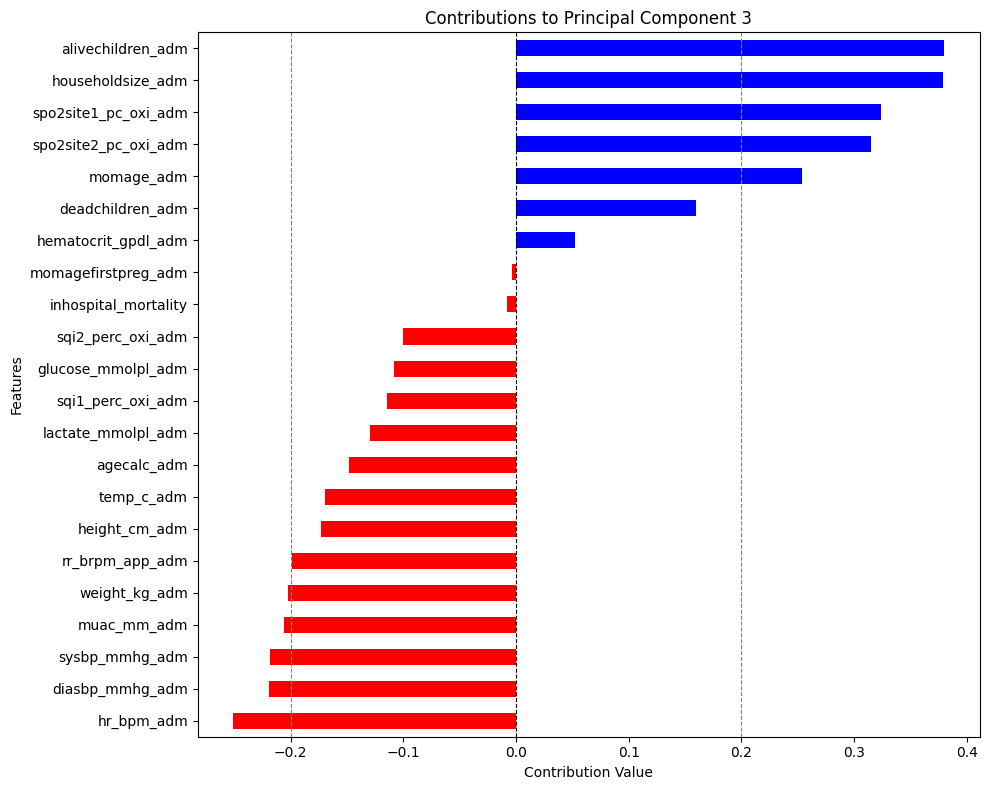

In [7]:
# Perform PCA on numerical columns
if not numerical_cols.empty:
    df_numerical = data[numerical_cols]

    # Standardize numerical data
    scaler = StandardScaler()
    standardized_numerical = scaler.fit_transform(df_numerical)

    # Apply PCA
    pca = PCA(n_components=3)
    pca_numerical = pca.fit_transform(standardized_numerical)

    # PCA explained variance ratio
    print("\nPCA Explained Variance Ratio (Numerical Features):", pca.explained_variance_ratio_)
    
    # visualize the contributions
    pca_components_df = pd.DataFrame(pca.components_.T, index=numerical_cols)

    # Sort contributions for each dimension
    sorted_pca_contributions = {
        f"Principal Component {pc+1}": pca_components_df[pc].sort_values(ascending=False)
        for pc in range(pca_components_df.shape[1])
    }

    # Display sorted contributions for numerical PCA
    for pc, sorted_contrib in sorted_pca_contributions.items():
        print(f"\n{pc} (Sorted Contributions):")
        print(sorted_contrib)
        diverging_bar_plot(sorted_contrib, pc)
else:
    print("No numerical columns to process.")
    # Sort contributions for each principal component (numerical)


Final PCA Explained Variance Ratio (Combined Features): [0.43977616 0.29077835 0.25225966]

Principal Component 1 (Sorted Contributions):

height_cm_adm           0.471392
weight_kg_adm           0.470944
agecalc_adm             0.440372
muac_mm_adm             0.358954
spo2site2_pc_oxi_adm    0.219759
spo2site1_pc_oxi_adm    0.206564
momage_adm              0.144376
alivechildren_adm       0.092141
householdsize_adm       0.086784
sqi2_perc_oxi_adm       0.081289
sqi1_perc_oxi_adm       0.075608
momagefirstpreg_adm     0.050288
diasbp_mmhg_adm         0.033766
deadchildren_adm        0.025034
lactate_mmolpl_adm      0.024003
hematocrit_gpdl_adm     0.015457
glucose_mmolpl_adm      0.007043
sysbp_mmhg_adm         -0.002295
inhospital_mortality   -0.035108
temp_c_adm             -0.060200
hr_bpm_adm             -0.160527
rr_brpm_app_adm        -0.239336
Name: 0, dtype: float64

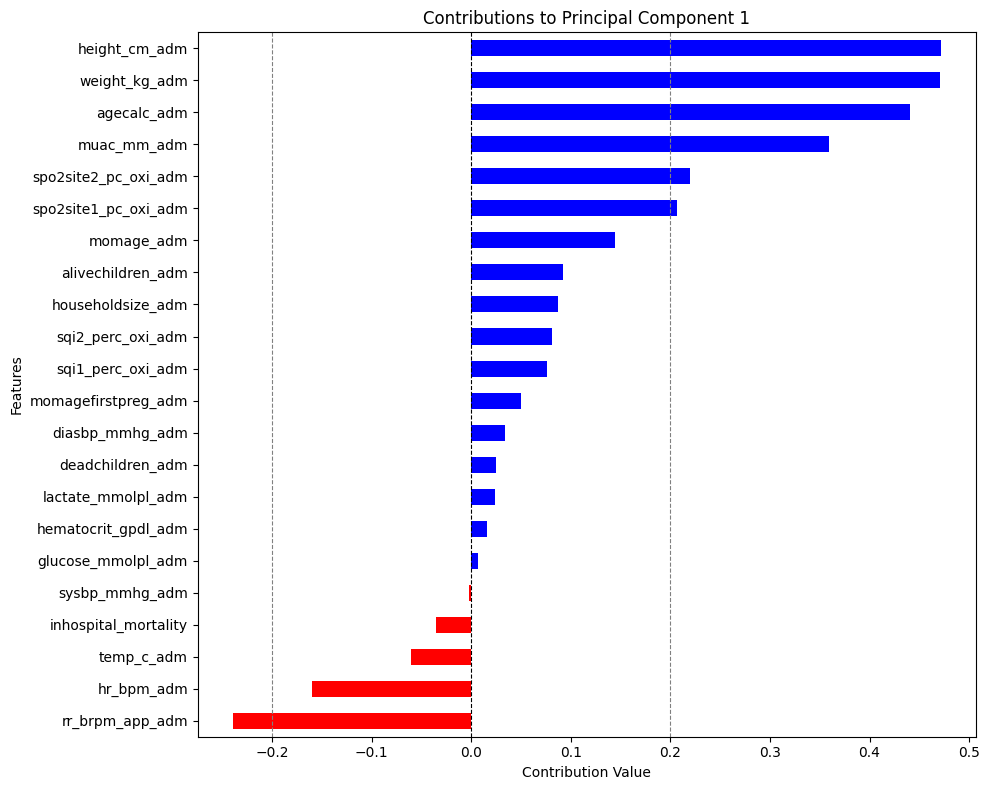

Principal Component 2 (Sorted Contributions):

alivechildren_adm       0.437862
householdsize_adm       0.405181
momage_adm              0.322408
deadchildren_adm        0.243641
rr_brpm_app_adm         0.235132
diasbp_mmhg_adm         0.177398
sysbp_mmhg_adm          0.140816
hr_bpm_adm              0.137937
lactate_mmolpl_adm      0.137796
temp_c_adm              0.131855
glucose_mmolpl_adm      0.116713
agecalc_adm             0.095497
height_cm_adm           0.080775
weight_kg_adm           0.080647
muac_mm_adm             0.001713
inhospital_mortality   -0.000539
momagefirstpreg_adm    -0.018842
hematocrit_gpdl_adm    -0.090387
sqi1_perc_oxi_adm      -0.125953
sqi2_perc_oxi_adm      -0.161844
spo2site2_pc_oxi_adm   -0.339160
spo2site1_pc_oxi_adm   -0.342673
Name: 1, dtype: float64

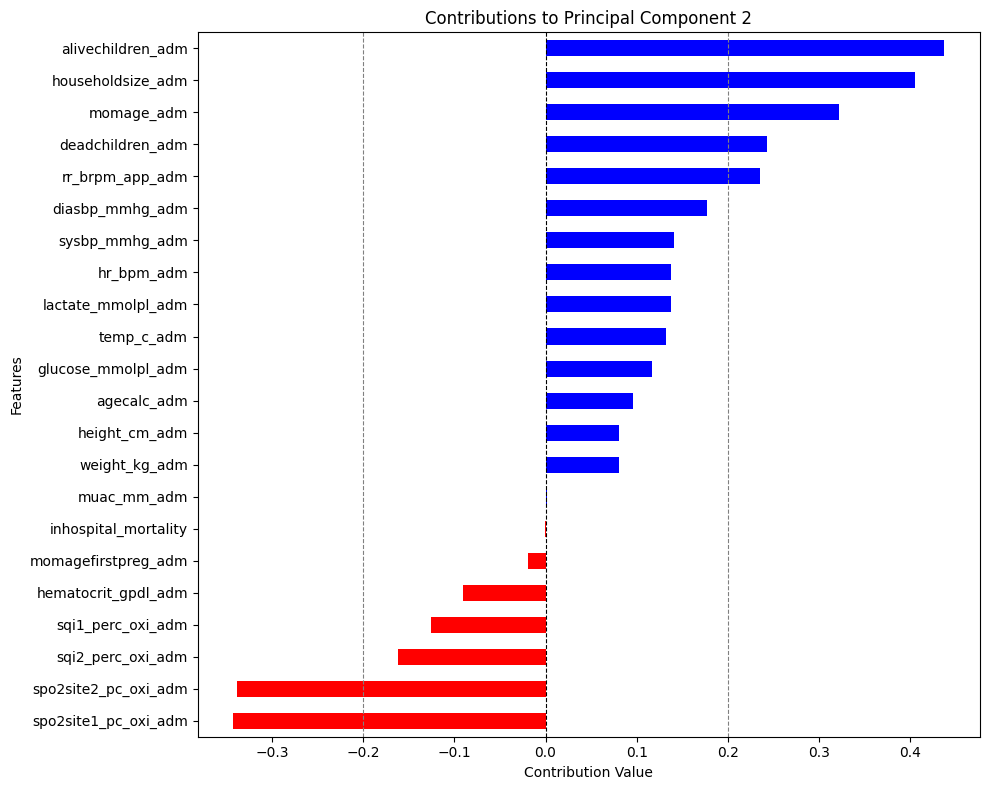

Principal Component 3 (Sorted Contributions):

alivechildren_adm       0.380339
householdsize_adm       0.378929
spo2site1_pc_oxi_adm    0.323696
spo2site2_pc_oxi_adm    0.315345
momage_adm              0.253797
deadchildren_adm        0.160094
hematocrit_gpdl_adm     0.052598
momagefirstpreg_adm    -0.003307
inhospital_mortality   -0.007877
sqi2_perc_oxi_adm      -0.099934
glucose_mmolpl_adm     -0.108072
sqi1_perc_oxi_adm      -0.114746
lactate_mmolpl_adm     -0.129823
agecalc_adm            -0.147998
temp_c_adm             -0.169721
height_cm_adm          -0.173563
rr_brpm_app_adm        -0.199268
weight_kg_adm          -0.202769
muac_mm_adm            -0.205576
sysbp_mmhg_adm         -0.218666
diasbp_mmhg_adm        -0.219630
hr_bpm_adm             -0.250987
Name: 2, dtype: float64

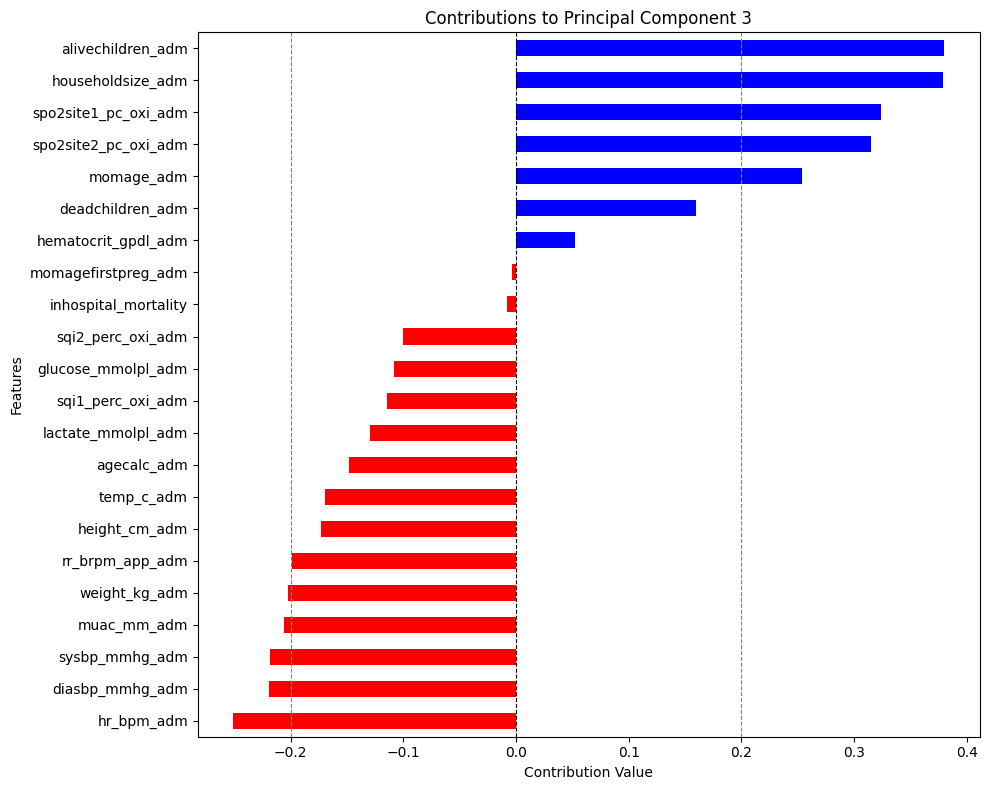

In [8]:
# Combine MCA and PCA results
if not categorical_cols.empty and not numerical_cols.empty:
    # Get MCA components for categorical features
    mca_components = mca.transform(df_categorical)

    # Combine numerical and categorical components
    combined_components = np.hstack((mca_components, pca_numerical))

    # Reduce to 3 dimensions
    final_pca = PCA(n_components=3)
    reduced_data = final_pca.fit_transform(combined_components)

    # Print final explained variance ratio
    print("\nFinal PCA Explained Variance Ratio (Combined Features):", final_pca.explained_variance_ratio_)
    
    # visualize the contributions
    pca_components_df = pd.DataFrame(pca.components_.T, index=numerical_cols)

    # Sort contributions for each dimension
    sorted_pca_contributions = {
        f"Principal Component {pc+1}": pca_components_df[pc].sort_values(ascending=False)
        for pc in range(pca_components_df.shape[1])
    }

    # Display sorted contributions for numerical PCA
    for pc, sorted_contrib in sorted_pca_contributions.items():
        print(f"\n{pc} (Sorted Contributions):")
        print(sorted_contrib)
        diverging_bar_plot(sorted_contrib, pc)
else:
    print("No numerical columns to process.")
    # Sort contributions for each principal component (numerical)